In [17]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector

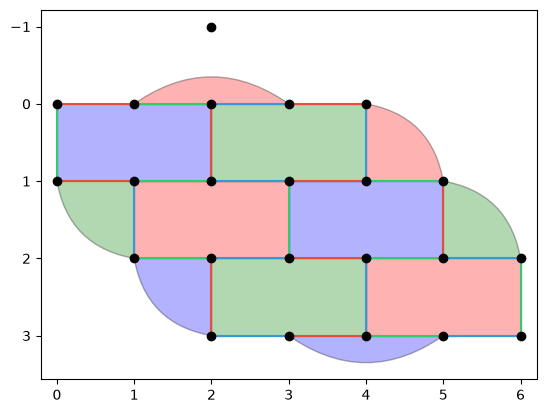

In [18]:
s = CSSHoneycomb()
s.plot_surface(show=False)
plt.savefig("testing/output/small_example.png")
plt.show()

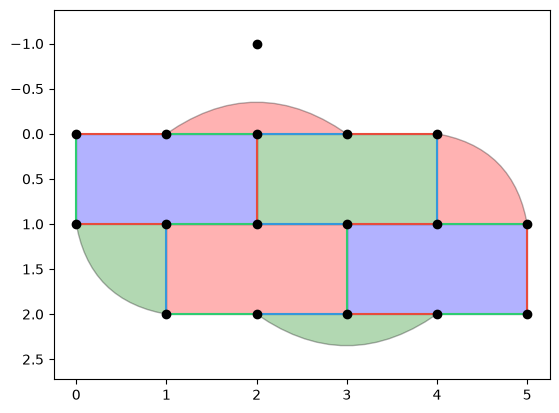

In [19]:
# TODO do we use letters or words?
COLOUR_MAP = {
    'r' : 'red',
    'g' : 'green',
    'b' : 'blue'
}

def measurement_cycle(honey: CSSHoneycomb, cycle=["rZ", "gX", "bZ", "rX", "gZ", "bX"]):
    """
    measure our stabilizers
    """

    string = ""
    for m in cycle:
        
        if m == "gZ":
            print("" ,end="")
        
        colour = COLOUR_MAP[m[0]]
        flavour = m[1]

        string += f"#{colour}{flavour}\n"
        string += honey.get_measurement(colour, flavour) + "\n"
        string += honey.tick()
    
    return string

import json

cycle = ["rX", "gZ", "bX", "rZ", "gX", "bZ"]
s = CSSHoneycomb(ncols=5, nrows=3)
s.set_measurement_cycle(cycle)
s.plot_surface()
string = s.initialise_circuit()
raw = json.load(open("config/5x3.json"))
initialisation = {tuple(q["pos"]): q["init"] for q in raw["qubits"]}
string += s.prepare_qubits(initialisation)
string += measurement_cycle(s, cycle=cycle)

In [20]:
c = stim.Circuit(string)

DETECTOR(2.25, 0.0, 11) rec[-7] rec[-1] 
DETECTOR(0.5, 1.25, 17) rec[-7] rec[-3] 
DETECTOR(1.0, 0.5, 27) rec[-41] rec[-40] rec[-38] rec[-8] rec[-7] rec[-6] 
DETECTOR(4.0, 1.5, 27) rec[-37] rec[-36] rec[-35] rec[-5] rec[-4] rec[-2] 
DETECTOR(4.25, 0.5, 27) rec[-4] rec[-1] 
DETECTOR(2.0, 1.5, 31) rec[-40] rec[-39] rec[-37] rec[-7] rec[-6] rec[-5] 
DETECTOR(2.25, 0.0, 31) rec[-41] rec[-35] rec[-9] rec[-3] 


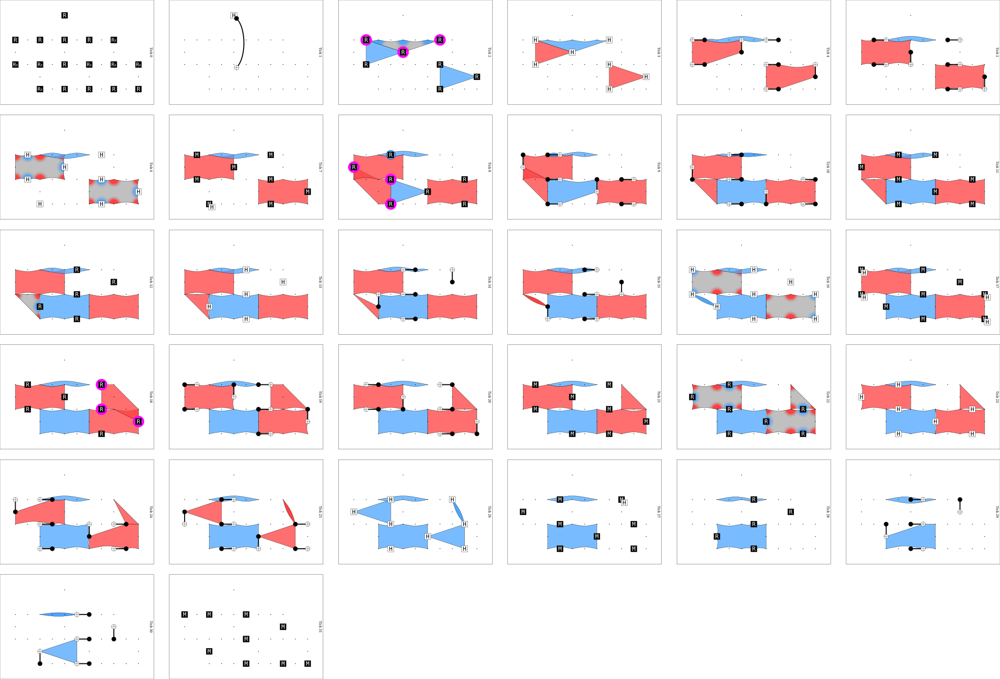

In [21]:
for line in string.splitlines():
    if "DETECTOR" in line:
        print(line)
c.diagram("detslice-with-ops-svg")


In [22]:
# looks like we are missing Z boundary stabilizer

In [23]:
len(c.shortest_graphlike_error()) # TODO

ValueError: The circuit contains non-deterministic detectors.

To make an SVG picture of the problem, you can use the python API like this:
    your_circuit.diagram('detslice-with-ops-svg', tick=range(13, 23), filter_coords=['D4', ])
or the command line API like this:
    stim diagram --in your_circuit_file.stim --type detslice-with-ops-svg --tick 13:23 --filter_coords D4 > output_image.svg

This was discovered while analyzing a Z-basis reset (R) on:
    qubit 31 [coords (5, 1.5)]

The collapse anti-commuted with these detectors/observables:
    D4 [coords (4.25, 0.5, 27)]

The backward-propagating error sensitivity for D4 was:
    X5 [coords (4, 0)]
    X10 [coords (4, 1)]
    X11 [coords (5, 1)]
    X22 [coords (3.5, 0)]
    X29 [coords (3.5, 1)]
    X31 [coords (5, 1.5)]

Circuit stack trace:
    during TICK layer #19 of 33
    at instruction #79 [which is R 18 20 22 24 29 31 34]

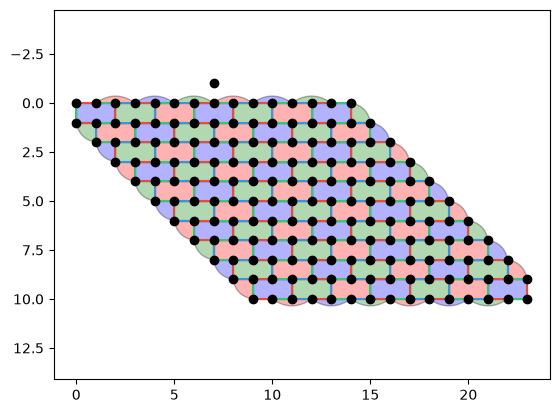

In [ ]:
# TODO do we use letters or words?
cycle = ["rZ", "gX", "bZ", "rX", "gZ", "bX", "rZ", "gX", "bZ", "rX", "gZ", "bX"]

s = CSSHoneycomb(ncols=15, nrows=11)
s.set_measurement_cycle(cycle)
s.plot_surface()
string = s.initialise_circuit()
string += s.prepare_qubits()
string += measurement_cycle(s, cycle)

In [ ]:
c = stim.Circuit(string)
c.diagram("detslice-with-ops-svg")